In [4]:
import requests
import pandas as pd
import matplotlib.pyplot as plt
import json
import os
from dotenv import load_dotenv

load_dotenv()
client_id = os.getenv("FROST_CLIENT_ID")
client_secret = os.getenv("FROST_CLIENT_SECRET")


In [5]:
def get_weather_data(
    station_id: str,
    elements: str,
    start_date: str,
    end_date: str,
) -> pd.DataFrame:
    """
    Fetch selected weather observations from Frost API.

    Args:
        station_id: Frost station ID, e.g. "SN18700".
        elements: Measurement element ID, e.g. "air_temperature".
        start_date: Start date in YYYY-MM-DD format.
        end_date: End date in YYYY-MM-DD format.

    Returns:
        A DataFrame containing the requested observations.

    Raises:
        ValueError: If the Frost Client ID is missing.
        requests.HTTPError: If the API request fails.
        requests.RequestException: If a connection error occurs.
    """
    if not client_id:
        raise ValueError("FROST_CLIENT_ID was not found.")

    url = "https://frost.met.no/observations/v0.jsonld"

    params = {
        "sources": station_id,
        "elements": elements,
        "referencetime": f"{start_date}/{end_date}",
    }

    response = requests.get(
        url,
        auth=(client_id, ""),
        params=params,
        timeout=30,
    )
    response.raise_for_status()

    data = response.json()["data"]

    if not data:
        return pd.DataFrame()

    df = pd.json_normalize(
        data,
        record_path="observations",
        meta=["sourceId", "referenceTime"],
    )

    return df


Task 1: Temperature

In [6]:
# Fetching weather data for 2025 from Frost API
df_2025 = get_weather_data(
    station_id="SN17850",
    elements="mean(air_temperature P1D)",
    start_date="2025-01-01",
    end_date="2025-12-31",
)

display(df_2025.head())


,elementId,value,unit,timeOffset,timeResolution,timeSeriesId,performanceCategory,exposureCategory,qualityCode,level.levelType,level.unit,level.value,sourceId,referenceTime
0,mean(air_temperature P1D),-5.2,degC,PT0H,P1D,0,C,1,0.0,height_above_ground,m,2,SN17850:0,2025-01-01T00:00:00.000Z
1,mean(air_temperature P1D),-2.8,degC,PT6H,P1D,0,C,1,NaN,height_above_ground,m,2,SN17850:0,2025-01-01T00:00:00.000Z
2,mean(air_temperature P1D),-11.5,degC,PT0H,P1D,0,C,1,0.0,height_above_ground,m,2,SN17850:0,2025-01-02T00:00:00.000Z
3,mean(air_temperature P1D),-7.2,degC,PT6H,P1D,0,C,1,NaN,height_above_ground,m,2,SN17850:0,2025-01-02T00:00:00.000Z
4,mean(air_temperature P1D),-8.9,degC,PT0H,P1D,0,C,1,0.0,height_above_ground,m,2,SN17850:0,2025-01-03T00:00:00.000Z


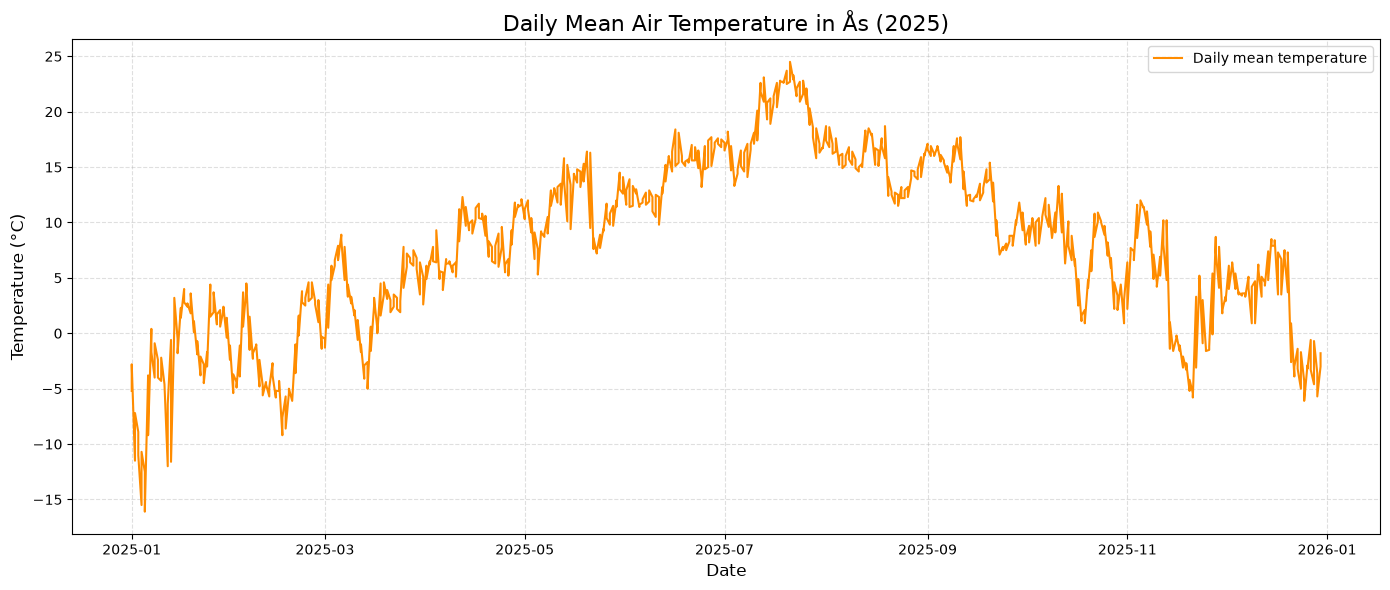

In [7]:
# Making a plot of the daily mean air temperature in Ås for 2025
plt.figure(figsize=(14, 6))

plt.plot(
    pd.to_datetime(df_2025["referenceTime"]),
    df_2025["value"],
    color="darkorange",
    linewidth=1.5,
    label="Daily mean temperature"
)

plt.title("Daily Mean Air Temperature in Ås (2025)", fontsize=16)
plt.xlabel("Date", fontsize=12)
plt.ylabel("Temperature (°C)", fontsize=12)

plt.grid(True, linestyle="--", alpha=0.4)
plt.legend()
plt.tight_layout()
plt.show()

In [8]:
# Calculate summary statistics for 2025
temperature = df_2025["value"]

summary = pd.DataFrame({
    "Statistic": ["Mean", "Median", "Minimum", "Maximum"],
    "Temperature (°C)": [
        temperature.mean(),
        temperature.median(),
        temperature.min(),
        temperature.max()
    ]
})

# Round temperatures to two decimal places
summary["Temperature (°C)"] = summary["Temperature (°C)"].round(2)

# Display the summary table
print("Summary of daily mean air temperature in Ås (2025)")
print(summary.to_string(index=False))

Summary of daily mean air temperature in Ås (2025)
Statistic  Temperature (°C)
     Mean              7.90
   Median              8.35
  Minimum            -16.10
  Maximum             24.50


Task 2: Precipitation

In [9]:

# Fetching precipitation data for 2025 from Frost API
df_precipitation_2025 = get_weather_data(
    station_id="SN17850",
    elements="sum(precipitation_amount P1D)",
    start_date="2025-01-01",
    end_date="2025-12-31",
)

# Keep the preferred time offset for daily precipitation
df_precipitation_2025 = df_precipitation_2025[
    df_precipitation_2025["timeOffset"] == "PT6H"
].copy()

display(df_precipitation_2025.head())

,elementId,value,unit,timeOffset,timeResolution,timeSeriesId,performanceCategory,exposureCategory,qualityCode,sourceId,referenceTime
1,sum(precipitation_amount P1D),6.6,mm,PT6H,P1D,0,C,2,0.0,SN17850:0,2025-01-01T00:00:00.000Z
3,sum(precipitation_amount P1D),1.9,mm,PT6H,P1D,0,C,2,0.0,SN17850:0,2025-01-02T00:00:00.000Z
5,sum(precipitation_amount P1D),0.1,mm,PT6H,P1D,0,C,2,0.0,SN17850:0,2025-01-03T00:00:00.000Z
7,sum(precipitation_amount P1D),0.0,mm,PT6H,P1D,0,C,2,0.0,SN17850:0,2025-01-04T00:00:00.000Z
9,sum(precipitation_amount P1D),0.0,mm,PT6H,P1D,0,C,2,0.0,SN17850:0,2025-01-05T00:00:00.000Z


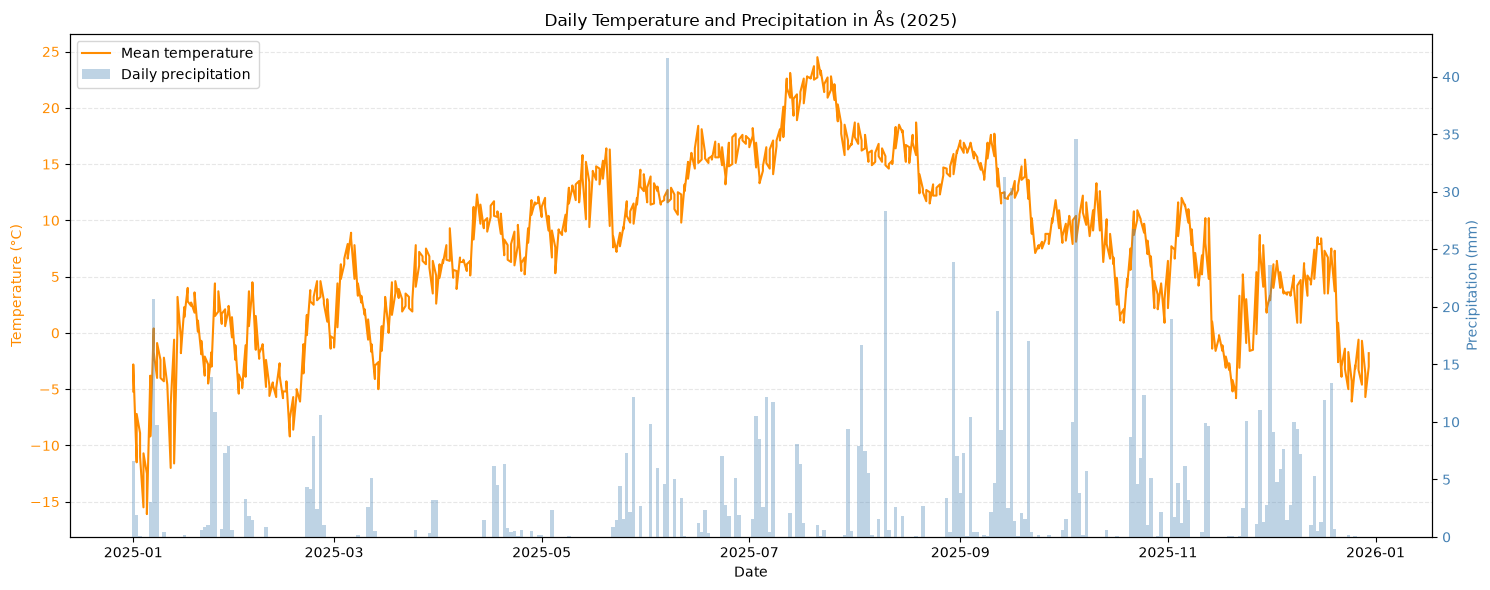

In [10]:
fig, ax1 = plt.subplots(figsize=(15, 6))

# Plot daily mean temperature as a line
ax1.plot(
    pd.to_datetime(df_2025["referenceTime"]),
    df_2025["value"],
    color="darkorange",
    linewidth=1.5,
    label="Mean temperature",
)

ax1.set_xlabel("Date")
ax1.set_ylabel("Temperature (°C)", color="darkorange")
ax1.tick_params(axis="y", labelcolor="darkorange")

# Create a second y-axis for precipitation
ax2 = ax1.twinx()

ax2.bar(
    pd.to_datetime(df_precipitation_2025["referenceTime"]),
    df_precipitation_2025["value"],
    color="steelblue",
    alpha=0.35,
    width=1.0,
    label="Daily precipitation",
)

ax2.set_ylabel("Precipitation (mm)", color="steelblue")
ax2.tick_params(axis="y", labelcolor="steelblue")
ax2.set_ylim(bottom=0)

# Add title and combined legend
ax1.set_title("Daily Temperature and Precipitation in Ås (2025)")

lines, labels = ax1.get_legend_handles_labels()
bars, bar_labels = ax2.get_legend_handles_labels()
ax1.legend(lines + bars, labels + bar_labels, loc="upper left")

ax1.grid(True, axis="y", linestyle="--", alpha=0.3)
fig.tight_layout()
plt.show()


Task 3: Historical temperature data

In [11]:
df_1925 = get_weather_data(
    station_id="SN17850",
    elements="mean(air_temperature P1D)",
    start_date="1925-01-01",
    end_date="1925-12-31",
)

display(df_1925.head())

,elementId,value,unit,timeOffset,timeResolution,timeSeriesId,performanceCategory,exposureCategory,qualityCode,level.levelType,level.unit,level.value,sourceId,referenceTime
0,mean(air_temperature P1D),1.3,degC,PT0H,P1D,0,C,1,2,height_above_ground,m,2,SN17850:0,1925-01-01T00:00:00.000Z
1,mean(air_temperature P1D),4.1,degC,PT0H,P1D,0,C,1,2,height_above_ground,m,2,SN17850:0,1925-01-02T00:00:00.000Z
2,mean(air_temperature P1D),2.1,degC,PT0H,P1D,0,C,1,2,height_above_ground,m,2,SN17850:0,1925-01-03T00:00:00.000Z
3,mean(air_temperature P1D),0.1,degC,PT0H,P1D,0,C,1,2,height_above_ground,m,2,SN17850:0,1925-01-04T00:00:00.000Z
4,mean(air_temperature P1D),-2.2,degC,PT0H,P1D,0,C,1,2,height_above_ground,m,2,SN17850:0,1925-01-05T00:00:00.000Z


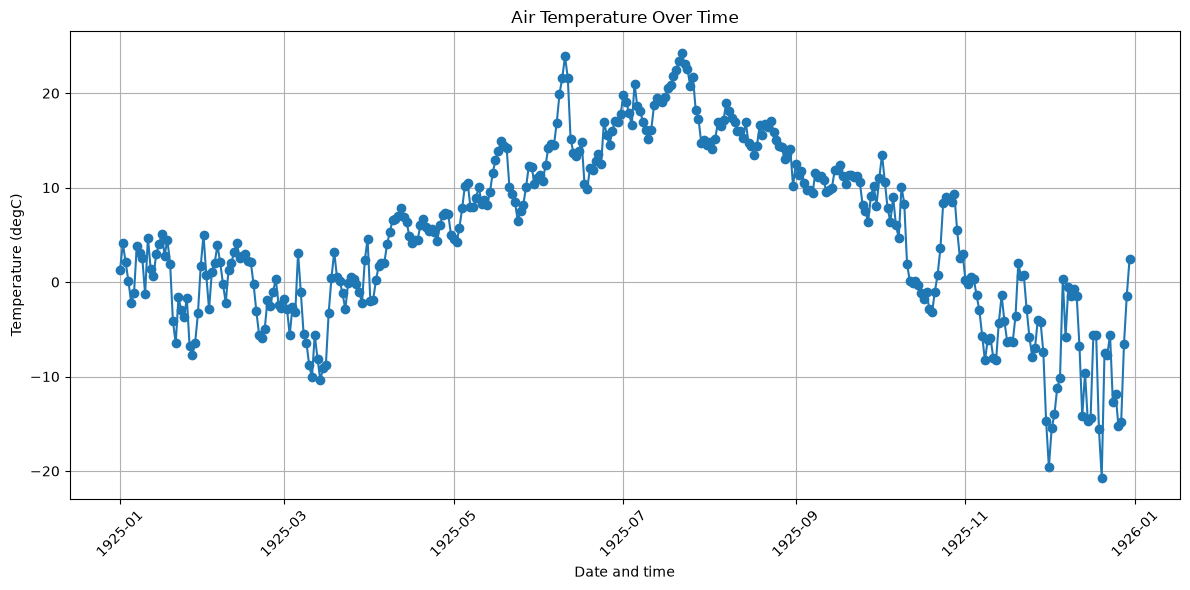

,Statistic,Temperature (°C)
0,Mean,5.31
1,Median,5.30
2,Min,-20.70
3,Max,24.30


In [12]:
# Check that data is available
if df_1925.empty:
    print("No weather data found for the selected period.")

else:
    # Convert observation times to datetime
    df_1925["referenceTime"] = pd.to_datetime(df_1925["referenceTime"])

    # Sort observations by time
    df = df_1925.sort_values("referenceTime")

    # Create the plot
    plt.figure(figsize=(12, 6))
    plt.plot(
        df_1925["referenceTime"],
        df_1925["value"],
        marker="o",
        linestyle="-",
    )

    # Add labels and title
    plt.xlabel("Date and time")
    plt.ylabel(f"Temperature ({df_1925['unit'].iloc[0]})")
    plt.title("Air Temperature Over Time")

    # Improve layout
    plt.xticks(rotation=45)
    plt.grid(True)
    plt.tight_layout()

    # Display the plot
    plt.show()


# Calculate summary statistics for the year
summary_table = pd.DataFrame({
    "Statistic": ["Mean", "Median", "Min", "Max"],
    "Temperature (°C)": [
        df_1925["value"].mean(),
        df_1925["value"].median(),
        df_1925["value"].min(),
        df_1925["value"].max(),
    ],
})

# Round values to two decimal places
summary_table["Temperature (°C)"] = (
    summary_table["Temperature (°C)"].round(2)
)

# Display summary table
display(summary_table)


Oppgaven oppdateres etter oppgave 1 er ferdigstilt....
1. mean.temp fra 2025 legges inn i plot sammen med mean.temp for 1925
2. oppsummeringstabell oppdateres med tall fra 2025. legg til kolonnenavn "2025" og "1925"
3. Gjerne sammenligne innhentningskoder mellom task 1 og task 3. trenger bare bruke en gjennom hele oppgaven.
4. sammenlign også oppsett av oppsummeringstabell, slik at disse blir like gjennom oppgaven.
5. trenger ikke å importere flere plasser i oppgaven. foreslår å sammle alle importeringer til en code-rute. får da ogsa en samlet oversikt over import.

Task 5: Moving average temperature

In [13]:
def moving_average(temperature, window=7):
    """
    Calculate the moving average of temperature.

    Args:
        temperature: A pandas Series containing daily temperatures.
        window: Number of days used to calculate the moving average.

    Returns:
        A pandas Series containing the moving average.
    """
    return temperature.rolling(window=window).mean()


In [14]:
# Calculate the 7-day moving average
df_2025["moving_average"] = moving_average(
    df_2025["value"],
    window=7
)

# Display the first rows
display(df_2025[["referenceTime", "value", "moving_average"]].head(10))

,referenceTime,value,moving_average
0,2025-01-01T00:00:00.000Z,-5.2,NaN
1,2025-01-01T00:00:00.000Z,-2.8,NaN
2,2025-01-02T00:00:00.000Z,-11.5,NaN
3,2025-01-02T00:00:00.000Z,-7.2,NaN
4,2025-01-03T00:00:00.000Z,-8.9,NaN
5,2025-01-03T00:00:00.000Z,-11.0,NaN
6,2025-01-04T00:00:00.000Z,-15.5,-8.871429
7,2025-01-04T00:00:00.000Z,-10.7,-9.657143
8,2025-01-05T00:00:00.000Z,-12.5,-11.042857
9,2025-01-05T00:00:00.000Z,-16.1,-11.700000


In [15]:
df_2025["referenceTime"] = pd.to_datetime(df_2025["referenceTime"])
df_2025 = df_2025.sort_values("referenceTime").reset_index(drop=True)

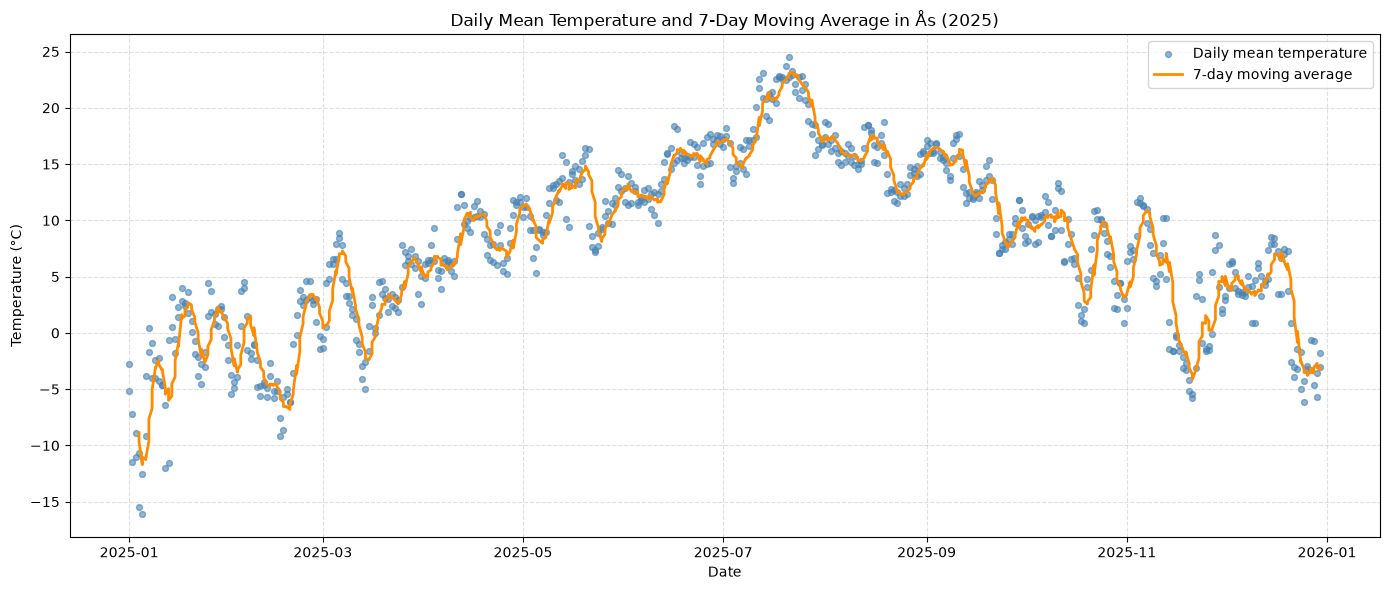

In [16]:
plt.figure(figsize=(14, 6))

# Plot daily temperatures as points
plt.scatter(
    pd.to_datetime(df_2025["referenceTime"]),
    df_2025["value"],
    color="steelblue",
    s=18,
    alpha=0.6,
    label="Daily mean temperature"
)

# Plot the 7-day moving average as a line
plt.plot(
    pd.to_datetime(df_2025["referenceTime"]),
    df_2025["moving_average"],
    color="darkorange",
    linewidth=2,
    label="7-day moving average"
)

plt.title("Daily Mean Temperature and 7-Day Moving Average in Ås (2025)")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")

plt.grid(True, linestyle="--", alpha=0.4)
plt.legend()
plt.tight_layout()
plt.show()
